# Volatility-Volume-based Order Management — **v2 (corrected)**

**Columbia University — IEOR4703 Monte Carlo Simulation Methods (Hirsa) · Term Project 2**

> *Given a trade decision to buy or sell, at what price level should we place a limit
> order — conditioned on the current market regime — to maximize expected execution quality?*

---

### What changed in v2 (read me first)

This revision addresses a review of the v1 notebook. Each change is tagged in the
code with a `# [FIX n]` comment and explained in the markdown above the relevant
section. Summary:

| Tag | Severity | What was wrong in v1 | What v2 does |
|----|----------|----------------------|--------------|
| **FIX 2** | **Critical bug** | `build_epdf` updated the ePDF over the *entire* dataset (`range(burn_in, n)`), so the empirical distributions, the MC cache, and every optimal limit level `ℓ*` were fit on the out-of-sample **test** bars too. This is look-ahead / in-sample contamination. | Training stops at `test_start_idx`. The store now contains **only** in-sample bars. Verified by an explicit observation count. |
| **FIX 4** | Robustness bug | `build_ohlc` stepped through each day by **row position** (`range(0, n-tau+1, tau)`). With any missing 1-minute rows (gaps, halts), a "5-minute" bar could silently span 7+ wall-clock minutes, biasing the range upward. | OHLC bars are built on **time** boundaries via `resample`, and windows that are too incomplete are dropped. |
| **FIX 5** | Reporting inconsistency | The README's headline "net vs market" = `fill_rate × mean_improvement_filled`, but the code's *Net true improvement* averaged all limit trades **including** the close-price fallback — a different number. | Both numbers are computed and **labelled distinctly**: `net_vs_market` (execution alpha) and `realized_avg_all` (realized P&L incl. missed-fill cost). |
| **FIX 1** | Spec-fidelity refinement | Volatility state was binned on the EWMA **mean of range**; Algorithm 1 also produces an EWM **variance/std** (EWMV). | `VOL_PROXY` config lets you bin on `'ewmv'` (spec-faithful std) or `'range_mean'`. Default `'ewmv'`. |
| **FIX 6** | Definition refinement | Direction state used the previous bar's *intrabar* move `close_{j-1}−open_{j-1}`. The spec defines `Δx_{j-1} = x_j − x_{j-1}` on the **open** price. *(Note: v1 was **not** look-ahead — it correctly used `j-1`.)* | Direction now uses open-to-open `open_j − open_{j-1}`, which is known at the start of bar `j` (still strictly causal). |
| **FIX 3** | Clarity (not a bug) | README wording on the `ℓ*` objective was ambiguous. The v1 objective `ℓ × P(fill)` is internally coherent (unconditional expected ticks). | `MC_OBJECTIVE` makes the choice explicit: `'expected_ticks'` (default) or `'cond_on_fill'`. They often coincide because the survival function is monotone — documented inline. |

**How to give feedback:** every section opens with a short markdown rationale. If you
disagree with a modelling choice, the knob for it lives in **Section 0**.

---
## Section 0 — Configuration

All knobs live here. The two new knobs versus v1 are `VOL_PROXY` (FIX 1) and
`MC_OBJECTIVE` (FIX 3). `MIN_COMPLETENESS` (FIX 4) controls how much of a
τ-window must be present for the bar to be kept.

**Gradual testing:** the registry below includes synthetic `TINY` / `SMALL` /
`COVID` assets so you can validate the pipeline before pointing it at the real
NQ / GC CSVs. Set `ASSET` accordingly and run top to bottom. See `TESTING.md`.

In [4]:
# ─────────────────────────────────────────────
# SECTION 0 — CONFIGURATION  (edit only this cell)
# ─────────────────────────────────────────────
import os

# --- Asset & Data ---
ASSET            = 'COVID'      # 'TINY'/'SMALL'/'COVID' (synthetic) | 'NQ' | 'GC'
DATA_DIR         = '../data/'
MIN_BARS_PER_DAY = 350         # active-day filter (~90% of 390-min US session)
MIN_COMPLETENESS = 0.6         # [FIX 4] min fraction of a tau-window that must
                               #         be present for the OHLC bar to be kept

# --- Holding Period ---
TAU              = 5           # minutes; valid: 5, 10, 15, 30, 60

# --- AI Agent Signal ---
USE_AI_AGENT_SIGNAL = True     # True = AIAgent CSV; False = synthetic momentum

# --- EWMA State Engine ---
HALF_LIFE        = 20          # EWMA half-life in tau-bars
M_STATES         = 3           # volume regime bins
N_STATES         = 3           # volatility regime bins
K_STATES         = 3           # direction bins (down / flat / up)
DIR_THRESHOLD    = 1.0         # ticks; dead-band around zero for direction state
VOL_PROXY        = 'ewmv'      # [FIX 1] 'ewmv' (EWM std of range, spec) | 'range_mean'

# --- ePDF Builder ---
BURN_IN          = 300         # tau-bars before ePDF estimation begins
MIN_EPDF_SAMPLES = 30          # min obs per state cell before ePDF is trusted
SMOOTHING_ALPHA  = 0.5         # Laplace/Jeffreys pseudo-count per tick level

# --- Train / Test Split ---
TEST_START_FRAC  = 0.60        # first 60% = in-sample; last 40% = out-of-sample

# --- Monte Carlo Simulation ---
N_MC_PATHS       = 10_000
MC_CONFIDENCE    = 0.95
BOOTSTRAP_REPS   = 1_000
MC_OBJECTIVE     = 'expected_ticks'   # [FIX 3] 'expected_ticks' | 'cond_on_fill'

# --- Backtest & Order Placement ---
FILL_PROB_THRESHOLD = 0.60
QUEUE_HAIRCUT    = 0.92         # queue-position discount (1.0 = off)

# --- Synthetic Signal fallback (USE_AI_AGENT_SIGNAL = False only) ---
SIGNAL_TYPE      = 'momentum'
SIGNAL_LOOKBACK  = 10
SIGNAL_THRESHOLD = 1.0

# --- Reproducibility ---
RANDOM_SEED      = 42

print(f"Config: ASSET={ASSET}, TAU={TAU}min, states={M_STATES}x{N_STATES}x{K_STATES}, "
      f"vol_proxy={VOL_PROXY}, mc_objective={MC_OBJECTIVE}, "
      f"AI_signal={USE_AI_AGENT_SIGNAL}")

Config: ASSET=COVID, TAU=5min, states=3x3x3, vol_proxy=ewmv, mc_objective=expected_ticks, AI_signal=True


---
## Section 1 — Imports & Setup

In [5]:
# ─────────────────────────────────────────────
# SECTION 1 — IMPORTS & SETUP
# ─────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from collections import defaultdict
from datetime import datetime, timedelta, date
from pathlib import Path
from itertools import product
from typing import Dict, List, Optional, Tuple

np.random.seed(RANDOM_SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})
PALETTE = sns.color_palette('tab10')
print("Imports complete.")

Imports complete.


---
## Section 2 — Data Loading & Preprocessing

Unchanged in spirit from v1. Each CSV row is a 1-minute snapshot
`[excel_date, hour, min, price, price, price, price, volume]` (one representative
price per minute). Multiple expiry contracts are stitched at the volume-crossover
rollover date, and low-activity days are dropped.

The registry now carries the **synthetic test assets** alongside the real ones so
you can dry-run the whole pipeline. The `tick_size` and date windows live here.

In [6]:
# ─────────────────────────────────────────────
# SECTION 2 — DATA LOADING & PREPROCESSING
# ─────────────────────────────────────────────

# Asset registry: contracts + paired AIAgent file + (optional) date window.
# Synthetic TINY/SMALL/COVID assets let you test before touching real data.
ASSET_REGISTRY = {
    # ---- synthetic test assets (generated by make_test_data.py) ----
    'TINY':  {'folder': 'Test', 'contracts': ['TINYH20.csv'],
              'tick_size': 0.25, 'ai_agent': 'AIAgent_Tiny.csv',
              'date_start': None, 'date_end': None},
    'SMALL': {'folder': 'Test', 'contracts': ['SMALLH20.csv', 'SMALLM20.csv'],
              'tick_size': 0.25, 'ai_agent': 'AIAgent_Small.csv',
              'date_start': None, 'date_end': None},
    'COVID': {'folder': 'Test', 'contracts': ['COVIDH20.csv'],
              'tick_size': 0.25, 'ai_agent': 'AIAgent_Covid.csv',
              'date_start': None, 'date_end': None},
    # ---- real assets ----
    'NQ':    {'folder': 'Nasdaq', 'contracts': ['NQH20.csv', 'NQM20.csv', 'NQU20.csv'],
              'tick_size': 0.25, 'ai_agent': 'AIAgent_Nasdaq.csv',
              'date_start': date(2020, 1, 2), 'date_end': date(2020, 5, 31)},
    'GC':    {'folder': 'Gold', 'contracts': ['GCG24.csv', 'GCJ24.csv', 'GCM24.csv', 'GCQ24.csv'],
              'tick_size': 0.10, 'ai_agent': 'AIAgent_Gold.csv',
              'date_start': date(2024, 1, 2), 'date_end': date(2024, 5, 31)},
}
TICK_SIZE = ASSET_REGISTRY[ASSET]['tick_size']   # resolve from registry, not hand-set


def _excel_to_date(serial: int) -> datetime:
    """Excel serial integer -> datetime (Excel epoch is 1899-12-30)."""
    return datetime(1899, 12, 30) + timedelta(days=int(serial))


def _parse_contract(filepath: str) -> pd.DataFrame:
    """Parse one contract CSV -> DataFrame[price, volume] indexed by datetime."""
    rows = []
    with open(filepath) as f:
        for line in f:
            parts = line.strip().split(',')
            if len(parts) < 8:                      # need at least through volume
                continue
            try:
                ds, hh, mm = int(parts[0]), int(parts[1]), int(parts[2])
                price, vol = float(parts[3]), int(parts[7])
            except (ValueError, IndexError):
                continue
            rows.append({'datetime': _excel_to_date(ds).replace(hour=hh, minute=mm),
                         'price': price, 'volume': vol})
    df = pd.DataFrame(rows).set_index('datetime').sort_index()
    return df[df['volume'] > 0]


def _detect_rollover(front: pd.DataFrame, back: pd.DataFrame) -> Optional[datetime]:
    """First date where the back contract's daily volume exceeds the front's."""
    f = front['volume'].resample('D').sum().rename('front')
    b = back['volume'].resample('D').sum().rename('back')
    both = pd.concat([f, b], axis=1).dropna()
    cross = both[both['back'] > both['front']]
    return None if cross.empty else cross.index[0].to_pydatetime()


def _stitch_contracts(dfs: List[pd.DataFrame]) -> pd.DataFrame:
    """Stitch consecutive contracts at the volume-crossover rollover date."""
    if len(dfs) == 1:
        return dfs[0]
    result = dfs[0].copy()
    for back in dfs[1:]:
        roll = _detect_rollover(result, back) or result.index[-1]
        result = pd.concat([result[result.index < roll],
                            back[back.index >= roll]]).sort_index()
    return result


def _filter_active_days(df: pd.DataFrame, min_bars: int) -> pd.DataFrame:
    counts = df.groupby(df.index.date).size()
    valid = counts[counts >= min_bars].index
    return df[pd.Series(df.index.date, index=df.index).isin(valid)]


def load_data(asset: str, data_dir: str = DATA_DIR,
              min_bars_per_day: int = MIN_BARS_PER_DAY) -> pd.DataFrame:
    meta = ASSET_REGISTRY[asset]
    folder = Path(data_dir) / meta['folder']
    ds, de = meta.get('date_start'), meta.get('date_end')
    dfs = []
    for fname in meta['contracts']:
        fp = folder / fname
        if not fp.exists():
            print(f"  [warn] {fp} not found — skipping"); continue
        df = _parse_contract(str(fp))
        if ds: df = df[df.index.date >= ds]
        if de: df = df[df.index.date <= de]
        if df.empty: continue
        dfs.append(df)
        print(f"  Loaded {fname}: {len(df):,} rows ({df.index[0].date()} → {df.index[-1].date()})")
    if not dfs:
        raise FileNotFoundError(f"No data for {asset} in {folder}")
    clean = _filter_active_days(_stitch_contracts(dfs), min_bars_per_day)
    print(f"\n  → {asset}: {len(clean):,} bars / {clean.index.normalize().nunique()} active days "
          f"({clean.index[0].date()} → {clean.index[-1].date()})")
    return clean


# ── Run ──
print(f"Loading {ASSET} ...")
raw_df = load_data(ASSET)

daily_vol = raw_df['volume'].resample('D').sum()
fig, ax = plt.subplots(figsize=(13, 3))
ax.bar(daily_vol.index, daily_vol.values, width=0.8, color=PALETTE[0], alpha=0.7)
ax.set(title=f'{ASSET} — Daily Volume', xlabel='Date', ylabel='Total Volume')
plt.tight_layout(); plt.show()

Loading COVID ...
  [warn] ../data/Test/COVIDH20.csv not found — skipping


FileNotFoundError: No data for COVID in ../data/Test

---
## Section 3 — OHLC Reconstruction &nbsp; `# [FIX 4]`

**The v1 problem.** v1 walked each day in steps of `tau` rows:
`for start in range(0, n - tau + 1, tau)`. That assumes every τ consecutive
*rows* equal τ consecutive *minutes*. Futures 1-minute data routinely has
missing minutes (pre-open, micro-halts, thin prints). When a minute is missing,
a 5-row window can cover 6–8 wall-clock minutes, so its high−low range is
systematically inflated — and the ePDF inherits that bias.

**The v2 fix.** Build bars on **time** boundaries with `resample('{tau}min',
origin='start_day')`, then drop windows that are too incomplete
(`MIN_COMPLETENESS`). Now a "5-minute bar" always covers exactly one 5-minute
clock window. Non-overlapping windows are preserved (resample is non-overlapping
by construction), so the i.i.d. argument for the Monte Carlo step still holds.

In [ ]:
# ─────────────────────────────────────────────
# SECTION 3 — OHLC RECONSTRUCTION   [FIX 4: time-based windows]
# ─────────────────────────────────────────────

def build_ohlc(df: pd.DataFrame, tau: int,
               min_completeness: float = MIN_COMPLETENESS) -> pd.DataFrame:
    """
    Aggregate 1-min rows into NON-OVERLAPPING tau-min OHLC bars on TIME
    boundaries (not row position).

    [FIX 4] Why time-based:
      - resample() groups by wall-clock window, so a bar can never silently
        span more than tau minutes because of missing 1-min rows.
      - `origin='start_day'` aligns windows to the session start each day, so
        bars don't drift across days.
      - Windows with fewer than `min_completeness * tau` minutes present are
        dropped (early closes, data gaps) rather than producing a thin bar.
    """
    out = []
    need = max(1, int(np.ceil(min_completeness * tau)))
    for _, day_df in df.groupby(df.index.normalize()):
        agg = day_df.resample(f'{tau}min', origin='start_day').agg(
            open=('price', 'first'), high=('price', 'max'),
            low=('price', 'min'),    close=('price', 'last'),
            volume=('volume', 'sum'), n_min=('price', 'size'))
        agg = agg[agg['n_min'] >= need]          # drop too-incomplete windows
        out.append(agg)
    ohlc = pd.concat(out).dropna(subset=['open', 'high', 'low', 'close'])
    return ohlc.drop(columns='n_min').sort_index()


# ── Run ──
print(f"Building {TAU}-min OHLC bars (time-based, completeness ≥ {MIN_COMPLETENESS:.0%})...")
ohlc_df = build_ohlc(raw_df, TAU)
print(f"  {len(ohlc_df):,} bars | avg raw range: "
      f"{(ohlc_df['high'] - ohlc_df['low']).mean():.4f} price units")

# Sanity check that the FIX worked: within-day gaps between consecutive bar
# starts must be exact multiples of tau minutes.
gaps = ohlc_df.index.to_series().groupby(ohlc_df.index.normalize()).diff().dropna()
bad = gaps[(gaps.dt.total_seconds() % (TAU * 60) != 0)]
print(f"  [FIX 4 check] within-day bar starts off the {TAU}-min grid: {len(bad)} (want 0)")
print(ohlc_df.head(3).to_string())

Building 5-min OHLC bars (time-based, completeness ≥ 60%)...


  8,346 bars | avg raw range: 54.8134 price units
  [FIX 4 check] within-day bar starts off the 5-min grid: 0 (want 0)
                       open     high      low    close  volume
datetime                                                      
2020-01-02 09:30:00  8796.5  8800.00  8796.50  8799.75    5784
2020-01-02 09:35:00  8805.5  8805.50  8790.25  8790.25    5893
2020-01-02 09:40:00  8782.5  8787.75  8778.75  8778.75    5676


---
## Section 4 — Range Computation &nbsp; `# [FIX 6 def.]`

Ranges in integer tick units make the ePDF a discrete PMF on `{0,1,2,...}`.
Identity `R = R_up + R_dn` holds after rounding because
`(H−L) = (H−O) + (O−L)`.

**`[FIX 6]` direction variable.** The spec defines the direction quantity as
`Δx_{j-1} = x_j − x_{j-1}` where `x` is the **open** price. v1 instead used the
previous bar's *intrabar* move `close_{j-1} − open_{j-1}`. Both are causal (no
look-ahead), but they measure different things. v2 computes `delta_x = open_j −
open_{j-1}` to match the spec. We retain `delta_x_intrabar` because the synthetic
momentum signal (Section 8) is naturally expressed on it.

Range stats (5-min, tick=0.25):
             R     R_up     R_dn
count  8346.00  8346.00  8346.00
mean    219.25   111.49   107.76
std     239.66   188.92   184.05
min       5.00     0.00     0.00
25%      59.00     0.00     0.00
50%     137.00    41.00    38.00
75%     279.00   132.00   128.00
max    2318.00  1898.00  2318.00

Identity R = R_up + R_dn holds: 100.0000%


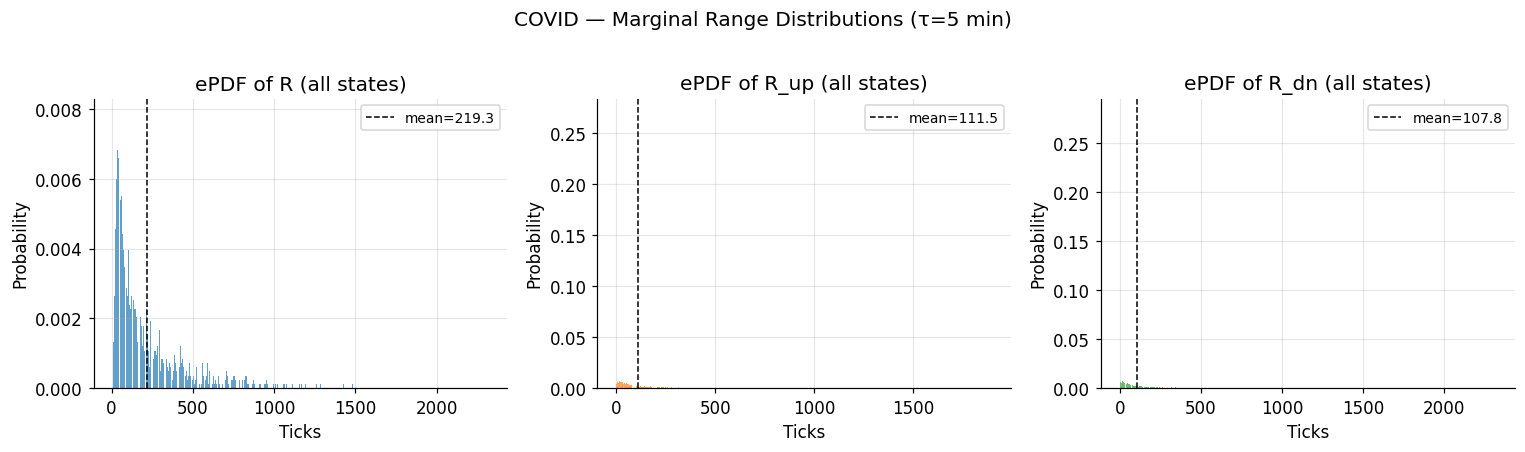

In [ ]:
# ─────────────────────────────────────────────
# SECTION 4 — RANGE COMPUTATION   [FIX 6: open-to-open delta_x]
# ─────────────────────────────────────────────

def compute_ranges(ohlc: pd.DataFrame, tick_size: float) -> pd.DataFrame:
    df = ohlc.copy()
    df['R']    = ((df['high'] - df['low'])  / tick_size).round().astype(int).clip(lower=0)
    df['R_up'] = ((df['high'] - df['open']) / tick_size).round().astype(int).clip(lower=0)
    df['R_dn'] = ((df['open'] - df['low'])  / tick_size).round().astype(int).clip(lower=0)

    # [FIX 6] spec direction quantity: change in OPEN across consecutive bars.
    df['delta_x']          = df['open'].diff()             # open_j - open_{j-1}
    # kept for the synthetic momentum signal only (NOT used for dir_state):
    df['delta_x_intrabar'] = df['close'] - df['open']
    return df


# ── Run ──
ohlc_df = compute_ranges(ohlc_df, TICK_SIZE)
print(f"Range stats ({TAU}-min, tick={TICK_SIZE}):")
print(ohlc_df[['R', 'R_up', 'R_dn']].describe().round(2).to_string())
identity = (ohlc_df['R'] == ohlc_df['R_up'] + ohlc_df['R_dn']).mean()
print(f"\nIdentity R = R_up + R_dn holds: {identity:.4%}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, color in zip(axes, ['R', 'R_up', 'R_dn'], PALETTE[:3]):
    vals = ohlc_df[col]; counts = vals.value_counts().sort_index()
    ax.bar(counts.index, counts.values / counts.sum(), color=color, alpha=0.7, width=0.8)
    ax.set(title=f'ePDF of {col} (all states)', xlabel='Ticks', ylabel='Probability')
    ax.axvline(vals.mean(), color='k', ls='--', lw=1, label=f'mean={vals.mean():.1f}')
    ax.legend(fontsize=9)
plt.suptitle(f'{ASSET} — Marginal Range Distributions (τ={TAU} min)', y=1.02)
plt.tight_layout(); plt.show()

---
## Section 5 — EWMA State Engine &nbsp; `# [FIX 1]`

Each bar is classified into `(vol_state, sig_state, dir_state)` using
exponentially-weighted moving statistics. Algorithm 1 from the spec is
implemented with a strict lag-1 update (`η_{j-1}` at step `j`), and the state
**bin thresholds** are recomputed from the EWMA history seen up to bar `j` only —
both are out-of-sample.

**`[FIX 1]` volatility proxy.** Algorithm 1 produces *both* an EWM mean and an
EWM variance/std (EWMV). v1 binned the volatility dimension on the EWMA **mean
of range**; the EWMV output was computed and discarded. The spec frames the
volatility dimension as a *variance* quantity, so v2 defaults
`VOL_PROXY='ewmv'` (bin on the EWM std of range) and keeps `'range_mean'`
available. Volume is always binned on the EWMA mean of volume.

*(Note on `[FIX 6]`: the direction state uses `delta_x = open_j − open_{j-1}`
evaluated at `j-1`, i.e. `open_{j-1} − open_{j-2}` — strictly causal.)*

Computing EWMA states (vol_proxy='ewmv')...


  Active bars (post burn-in): 8,046
  Volume: s0=9.8%, s1=50.2%, s2=40.0%
  Volatility: s0=6.1%, s1=44.6%, s2=49.3%
  Direction: s0=49.6%, s1=1.0%, s2=49.3%


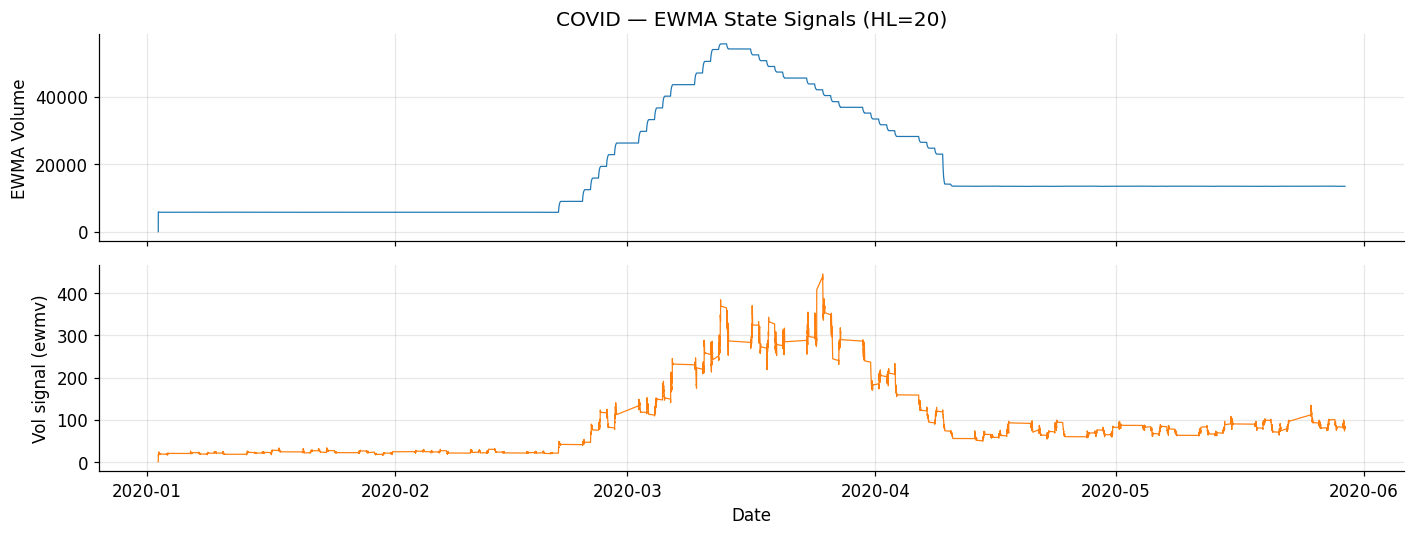

In [ ]:
# ─────────────────────────────────────────────
# SECTION 5 — EWMA STATE ENGINE   [FIX 1: ewmv vol proxy]
# ─────────────────────────────────────────────

def _ewma_recursive(series: np.ndarray, half_life: int) -> Tuple[np.ndarray, np.ndarray]:
    """
    Algorithm 1 (spec): recursive EWM mean and std. Uses series[j-1] at step j
    (strict lag-1) so nothing is forward-looking.
    Returns (ewma_mean, ewm_std).
    """
    lam = 2 ** (-1.0 / half_life)                # half-life decay factor
    n = len(series)
    ewma = np.zeros(n); ewmstd = np.zeros(n)
    sumW = sumWX = sumWSS = 0.0
    for j in range(1, n):
        eta = series[j - 1]
        if j == 1:
            sumW, sumWX = 1.0, eta
            ewma[j] = eta; sumWSS = 0.0; ewmstd[j] = 0.0
        else:
            sumW   = lam * sumW   + 1.0
            sumWX  = lam * sumWX  + eta
            ewma[j] = sumWX / sumW
            sumWSS = lam * sumWSS + (eta - ewma[j]) ** 2
            ewmstd[j] = np.sqrt(sumWSS / sumW)
    return ewma, ewmstd


def _bin_to_states(value: float, history: np.ndarray, n_states: int) -> int:
    """Assign `value` to a bin in [0, n_states-1] using quantile thresholds of
    `history` (out-of-sample: history is what was seen strictly before bar j)."""
    if len(history) < n_states + 1:
        return 0
    q = np.linspace(0, 100, n_states + 1)[1:-1]   # interior tercile breakpoints
    thr = np.percentile(history, q)
    return int(np.searchsorted(thr, value, side='right'))


def compute_ewma_states(df: pd.DataFrame,
                        tick_size: float = TICK_SIZE,
                        half_life: int   = HALF_LIFE,
                        m_states: int    = M_STATES,
                        n_states: int    = N_STATES,
                        k_states: int    = K_STATES,
                        dir_threshold: float = DIR_THRESHOLD,
                        burn_in: int     = BURN_IN,
                        vol_proxy: str   = VOL_PROXY) -> pd.DataFrame:
    """
    Add vol_state / sig_state / dir_state (and the underlying EWMA signals).
    All states are strictly out-of-sample. Bars before burn_in get state = -1.
    """
    df = df.copy(); n = len(df)
    volumes = df['volume'].values.astype(float)
    ranges  = df['R'].values.astype(float)
    dx      = df['delta_x'].values                     # [FIX 6] open-to-open

    ewma_volume, _           = _ewma_recursive(volumes, half_life)
    ewma_rng,   ewmstd_rng   = _ewma_recursive(ranges,  half_life)
    # [FIX 1] choose the volatility signal
    vol_signal = ewmstd_rng if vol_proxy == 'ewmv' else ewma_rng

    vol_state = np.full(n, -1, int)
    sig_state = np.full(n, -1, int)
    dir_state = np.full(n, -1, int)
    dir_tick  = dir_threshold * tick_size

    for j in range(burn_in, n):
        # history excludes index 0 (always 0 by Algorithm 1 init)
        vol_state[j] = _bin_to_states(ewma_volume[j], ewma_volume[1:j], m_states)
        sig_state[j] = _bin_to_states(vol_signal[j],  vol_signal[1:j],  n_states)
        pdx = dx[j - 1]
        if np.isnan(pdx): pdx = 0.0
        dir_state[j] = 0 if pdx < -dir_tick else (2 if pdx > dir_tick else 1)

    df['vol_state'] = vol_state
    df['sig_state'] = sig_state
    df['dir_state'] = dir_state
    df['ewma_volume'] = ewma_volume
    df['vol_signal']  = vol_signal
    return df


# ── Run ──
print(f"Computing EWMA states (vol_proxy='{VOL_PROXY}')...")
ohlc_df = compute_ewma_states(ohlc_df)
active = ohlc_df[ohlc_df['vol_state'] >= 0]
print(f"  Active bars (post burn-in): {len(active):,}")
for col, lab in [('vol_state', 'Volume'), ('sig_state', 'Volatility'), ('dir_state', 'Direction')]:
    pcts = (active[col].value_counts().sort_index() / len(active) * 100).round(1)
    print(f"  {lab}: " + ", ".join(f"s{k}={v}%" for k, v in pcts.items()))

fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes[0].plot(ohlc_df.index, ohlc_df['ewma_volume'], color=PALETTE[0], lw=0.8)
axes[0].set(ylabel='EWMA Volume', title=f'{ASSET} — EWMA State Signals (HL={HALF_LIFE})')
axes[1].plot(ohlc_df.index, ohlc_df['vol_signal'], color=PALETTE[1], lw=0.8)
axes[1].set(ylabel=f'Vol signal ({VOL_PROXY})', xlabel='Date')
plt.tight_layout(); plt.show()

---
## Section 6 — ePDF Builder &nbsp; `# [FIX 2 — critical]`

We build conditional empirical PMFs `P(R_up = ℓ | state)` and
`P(R_dn = ℓ | state)`, with Laplace smoothing (`α`) and a three-tier fallback
(state → marginal → market order).

### `[FIX 2]` — the critical bug

v1's `build_epdf` looped `for j in range(burn_in, n)` and called `store.update`
on **every** bar — including the out-of-sample test bars. The docstring claimed
the train/test boundary was handled "via `test_start_idx`," but `test_start_idx`
was only *returned*, never used to bound the loop. Consequences:

- The ePDF, the Monte-Carlo cache, and every optimal level `ℓ*` were fit on data
  that the backtest then "evaluated" — a textbook in-sample leak.
- It inflates fill-rate calibration and makes the headline numbers optimistic.

**v2** bounds the training loop to `[burn_in, test_start_idx)`. The cell prints an
independent count of the in-sample bars and asserts the store holds exactly that
many observations, so the absence of leakage is *verified*, not asserted.

In [ ]:
# ─────────────────────────────────────────────
# SECTION 6 — ePDF BUILDER   [FIX 2: train on in-sample bars only]
# ─────────────────────────────────────────────

class EpdfStore:
    """Online conditional empirical PMFs for R, R_up, R_dn keyed by state."""

    def __init__(self, smoothing_alpha=SMOOTHING_ALPHA, min_samples=MIN_EPDF_SAMPLES):
        self.alpha = smoothing_alpha
        self.min_samples = min_samples
        self._counts = defaultdict(
            lambda: {'R': np.zeros(1), 'R_up': np.zeros(1), 'R_dn': np.zeros(1)})
        self._marginal = {'R': np.zeros(1), 'R_up': np.zeros(1), 'R_dn': np.zeros(1)}

    @staticmethod
    def _extend(arr, size):
        return np.append(arr, np.zeros(size - len(arr))) if len(arr) < size else arr

    def update(self, state, R, R_up, R_dn):
        for store in (self._counts[state], self._marginal):
            store['R']    = self._extend(store['R'],    R + 1)
            store['R_up'] = self._extend(store['R_up'], R_up + 1)
            store['R_dn'] = self._extend(store['R_dn'], R_dn + 1)
            store['R'][R] += 1; store['R_up'][R_up] += 1; store['R_dn'][R_dn] += 1

    def _pmf(self, counts):
        s = counts + self.alpha                # Laplace/Jeffreys smoothing
        return s / s.sum()

    def _survival(self, counts):
        pmf = self._pmf(counts)
        return 1.0 - np.cumsum(pmf) + pmf      # P(X >= l)

    def _tot(self, state):  return int(self._counts[state]['R_up'].sum())
    def _marg(self):        return int(self._marginal['R_up'].sum())

    def get_pmf(self, state, d):
        if self._tot(state) >= self.min_samples:  return self._pmf(self._counts[state][d])
        if self._marg()     >= self.min_samples:  return self._pmf(self._marginal[d])
        return np.array([1.0])                  # tier 3 -> market order

    def get_survival(self, state, d):
        if self._tot(state) >= self.min_samples:  return self._survival(self._counts[state][d])
        if self._marg()     >= self.min_samples:  return self._survival(self._marginal[d])
        return np.array([1.0])

    def fill_prob(self, state, d, ell):
        sf = self.get_survival(state, d)
        return 0.0 if ell >= len(sf) else float(sf[ell])

    def state_count(self, state): return self._tot(state)


def build_epdf(df, burn_in=BURN_IN, test_start_frac=TEST_START_FRAC,
               smoothing_alpha=SMOOTHING_ALPHA, min_samples=MIN_EPDF_SAMPLES):
    """
    [FIX 2] Train ONLY on in-sample bars: the loop runs over
    [burn_in, test_start_idx).  Test bars (>= test_start_idx) never enter the
    store, so the MC cache and every optimal level are strictly out-of-sample.
    """
    store = EpdfStore(smoothing_alpha, min_samples)
    n = len(df)
    test_start_idx = int(n * test_start_frac)
    vs = df['vol_state'].values; ss = df['sig_state'].values; ds = df['dir_state'].values
    R = df['R'].values; Ru = df['R_up'].values; Rd = df['R_dn'].values

    for j in range(burn_in, test_start_idx):          # <-- the fix
        if vs[j] < 0 or ss[j] < 0 or ds[j] < 0:
            continue
        store.update((vs[j], ss[j], ds[j]), int(R[j]), int(Ru[j]), int(Rd[j]))
    return store, test_start_idx


# ── Run ──
print("Building conditional ePDFs (in-sample only)...")
epdf_store, test_start_idx = build_epdf(ohlc_df)
print(f"  Test period starts at bar index {test_start_idx} "
      f"({ohlc_df.index[test_start_idx].date()})")

# [FIX 2 verification] independently count the bars the store SHOULD contain.
idxs = np.arange(len(ohlc_df))
insample = ohlc_df.iloc[(idxs >= BURN_IN) & (idxs < test_start_idx)]
insample = insample[(insample['vol_state'] >= 0) & (insample['sig_state'] >= 0)
                    & (insample['dir_state'] >= 0)]
print(f"  [FIX 2 check] in-sample valid bars = {len(insample)}, "
      f"store total = {epdf_store._marg()}  "
      f"({'MATCH — no leakage' if len(insample) == epdf_store._marg() else 'MISMATCH!'})")

# Sample counts per state
sc = {(vs, ss, ds): epdf_store.state_count((vs, ss, ds))
      for vs, ss, ds in product(range(M_STATES), range(N_STATES), range(K_STATES))}
cdf = pd.Series(sc).rename('count').reset_index()
cdf.columns = ['vol', 'sig', 'dir', 'count']
print("\nSample counts per state:")
print(cdf.pivot_table(index=['vol', 'sig'], columns='dir', values='count', aggfunc='sum').to_string())
sparse = sum(1 for v in sc.values() if v < MIN_EPDF_SAMPLES)
print(f"\nSparse cells (<{MIN_EPDF_SAMPLES}): {sparse}/27 — fall back to marginal")

Building conditional ePDFs (in-sample only)...
  Test period starts at bar index 5007 (2020-04-01)
  [FIX 2 check] in-sample valid bars = 4707, store total = 4707  (MATCH — no leakage)

Sample counts per state:
dir         0   1     2
vol sig                
0   0      92   0    60
    1     110   2   125
    2     186  13   203
1   0      60   3    57
    1     130   9   149
    2     174  10   175
2   0      98   9   112
    1     156   5   143
    2    1338  17  1271

Sparse cells (<30): 9/27 — fall back to marginal


---
## Section 7 — Monte Carlo Execution Simulation &nbsp; `# [FIX 3]`

For each candidate limit level `ℓ`, we sample `N_MC_PATHS` range excursions from
the conditional ePDF, apply the queue haircut, and estimate the fill rate and
expected improvement. Bootstrap resampling gives a CI band on the fill rate.

### `[FIX 3]` — explicit objective (clarity, not a bug)

The optimal level solves, over the feasible set `{ℓ : haircut·P(fill|ℓ) ≥ θ}`:

- `MC_OBJECTIVE='expected_ticks'` → maximize `ℓ · P(fill|ℓ)` — **unconditional**
  expected ticks captured (an unfilled order contributes 0). This is exactly what
  v1 computed; the README wording "argmax E[improvement | state, ℓ]" is consistent
  with it once you read the expectation as being over the fill/no-fill outcome.
- `MC_OBJECTIVE='cond_on_fill'` → maximize `ℓ` — the widest feasible level (best
  price *conditional on filling*).

Because the survival function is monotone decreasing, the feasible set is a
low-`ℓ` interval and the two objectives **frequently select the same level**.
They diverge only when `ℓ·P(fill)` peaks strictly inside the feasible region.
The knob exists so the choice is explicit and auditable.

> **Note (model limitation, documented):** the bootstrap CI is computed on the raw
> ePDF counts and the queue haircut is applied afterward as a fixed scalar, so the
> band reflects estimation uncertainty in the *pre-haircut* survival curve.

Running Monte Carlo (objective='expected_ticks')...


  Cached 54 (state, direction) combinations


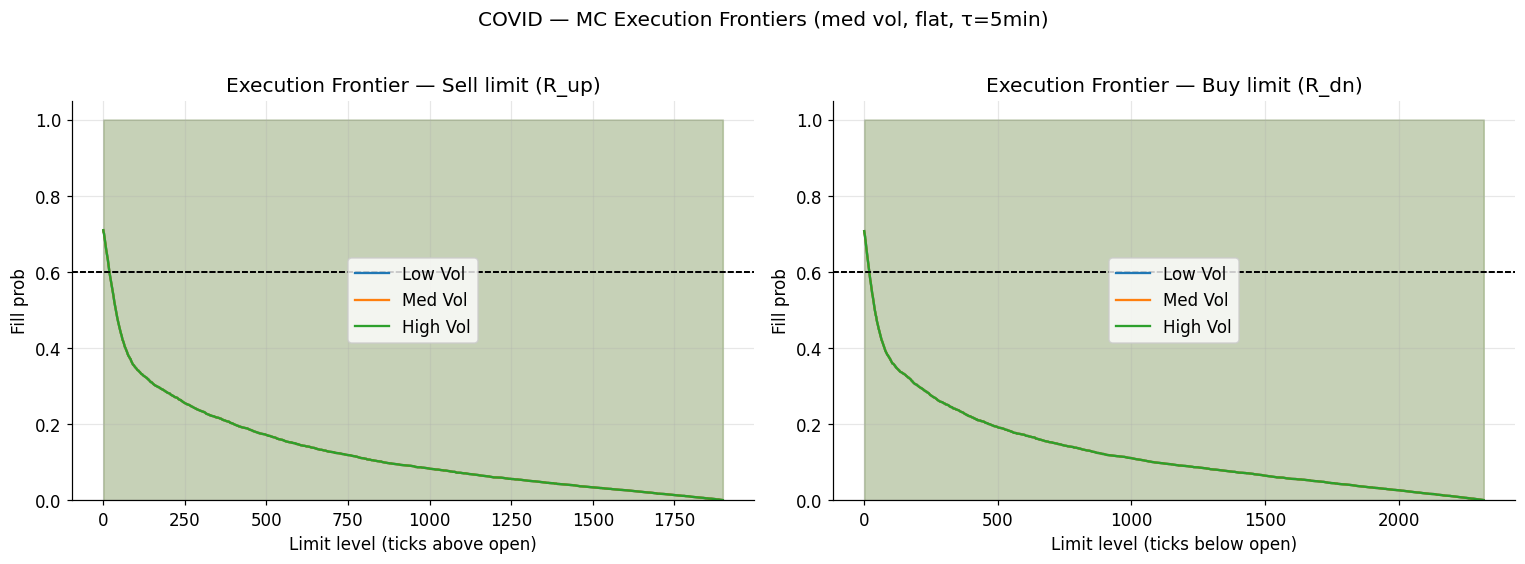


Optimal levels (ℓ*) at threshold=0.6, objective=expected_ticks:
State (v,s,d)     Sell ℓ*   Buy ℓ*  Sell mkt?  Buy mkt?
  (0, 0, 0)            17       12      False     False
  (0, 0, 1)            19       19      False     False
  (0, 0, 2)            10       28      False     False
  (0, 1, 0)            22        7      False     False
  (0, 1, 1)            19       19      False     False
  (0, 1, 2)            13       20      False     False
  (0, 2, 0)             7       15      False     False
  (0, 2, 1)            19       19      False     False
  (0, 2, 2)            15       11      False     False
  (1, 0, 0)            19       12      False     False
  (1, 0, 1)            19       19      False     False
  (1, 0, 2)            22       21      False     False
  (1, 1, 0)             8       16      False     False
  (1, 1, 1)            19       19      False     False
  (1, 1, 2)            12       12      False     False
  (1, 2, 0)            15        8     

In [ ]:
# ─────────────────────────────────────────────
# SECTION 7 — MONTE CARLO EXECUTION SIMULATION   [FIX 3: explicit objective]
# ─────────────────────────────────────────────

def mc_simulate_execution(store, state, direction,
                          n_paths=N_MC_PATHS,
                          fill_prob_threshold=FILL_PROB_THRESHOLD,
                          queue_haircut=QUEUE_HAIRCUT,
                          confidence=MC_CONFIDENCE,
                          bootstrap_reps=BOOTSTRAP_REPS,
                          objective=MC_OBJECTIVE,
                          seed=RANDOM_SEED) -> Dict:
    """
    Monte Carlo over candidate limit levels for one (state, direction).

    objective [FIX 3]:
      'expected_ticks' -> argmax  ell * haircut*P(fill)   (default; v1 behaviour)
      'cond_on_fill'   -> argmax  ell                     (widest feasible level)
    Feasibility in both cases: haircut * P(fill | ell) >= fill_prob_threshold.
    """
    rng = np.random.default_rng(seed)
    pmf = store.get_pmf(state, direction)
    L = len(pmf)
    samples = rng.choice(L, size=n_paths, p=pmf)        # simulated range draws

    ell_grid   = np.arange(1, max(2, L))
    fill_rates = queue_haircut * np.array([(samples >= e).mean() for e in ell_grid])
    exp_improvement = ell_grid * fill_rates              # unconditional E[ticks]

    # bootstrap CI on the fill rate (pre-haircut counts; haircut applied after).
    # Vectorized over reps; set bootstrap_reps=0 to skip (e.g. in sensitivity runs
    # where only optimal_ell / fill_rate are needed, not the CI band).
    counts = store._counts[state][direction]
    obs = np.repeat(np.arange(len(counts)), counts.astype(int))
    ci_lo = np.zeros(len(ell_grid)); ci_hi = np.ones(len(ell_grid))
    if bootstrap_reps > 0 and len(obs) >= store.min_samples:
        idx = rng.integers(0, len(obs), size=(bootstrap_reps, len(obs)))
        bs  = obs[idx]                                   # (reps, n_obs)
        boot = np.empty((bootstrap_reps, len(ell_grid)))
        for i, e in enumerate(ell_grid):                 # loop ell (~tens), vectorize reps
            boot[:, i] = (bs >= e).mean(axis=1)
        a = (1 - confidence) / 2
        ci_lo = queue_haircut * np.percentile(boot, 100 * a,       axis=0)
        ci_hi = queue_haircut * np.percentile(boot, 100 * (1 - a), axis=0)

    feasible = np.where(fill_rates >= fill_prob_threshold)[0]
    if len(feasible) == 0:
        optimal_ell, is_market = 0, True
    else:
        if objective == 'cond_on_fill':
            best = feasible[np.argmax(ell_grid[feasible])]
        else:  # 'expected_ticks'
            best = feasible[np.argmax(exp_improvement[feasible])]
        optimal_ell, is_market = int(ell_grid[best]), False

    return dict(ell_grid=ell_grid, fill_rate=fill_rates, exp_improvement=exp_improvement,
                ci_fill_lo=ci_lo, ci_fill_hi=ci_hi,
                optimal_ell=optimal_ell, is_market_order=is_market, objective=objective)


def build_mc_frontier_cache(store, m_states=M_STATES, n_states=N_STATES,
                            k_states=K_STATES, fill_prob_threshold=FILL_PROB_THRESHOLD,
                            queue_haircut=QUEUE_HAIRCUT, objective=MC_OBJECTIVE,
                            bootstrap_reps=BOOTSTRAP_REPS) -> Dict:
    """Pre-compute MC results for every (state, direction) so the backtest is O(1)/bar."""
    cache = {}
    for vs, ss, ds in product(range(m_states), range(n_states), range(k_states)):
        st = (vs, ss, ds)
        for d in ('R_up', 'R_dn'):
            cache[(st, d)] = mc_simulate_execution(
                store, st, d, fill_prob_threshold=fill_prob_threshold,
                queue_haircut=queue_haircut, objective=objective,
                bootstrap_reps=bootstrap_reps)
    return cache


# ── Run ──
print(f"Running Monte Carlo (objective='{MC_OBJECTIVE}')...")
mc_cache = build_mc_frontier_cache(epdf_store)
print(f"  Cached {len(mc_cache)} (state, direction) combinations")

# Execution frontier for the 3 volatility states (medium volume, flat direction)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = {0: 'Low Vol', 1: 'Med Vol', 2: 'High Vol'}
for ss, color in zip(range(N_STATES), PALETTE[:3]):
    state = (1, ss, 1)
    for k, direction in enumerate(['R_up', 'R_dn']):
        res = mc_cache[(state, direction)]; ax = axes[k]
        ax.plot(res['ell_grid'], res['fill_rate'], color=color, label=labels[ss])
        ax.fill_between(res['ell_grid'], res['ci_fill_lo'], res['ci_fill_hi'],
                        color=color, alpha=0.15)
        ax.axhline(FILL_PROB_THRESHOLD, color='k', ls='--', lw=1)
axes[0].set(title='Execution Frontier — Sell limit (R_up)',
            xlabel='Limit level (ticks above open)', ylabel='Fill prob')
axes[1].set(title='Execution Frontier — Buy limit (R_dn)',
            xlabel='Limit level (ticks below open)', ylabel='Fill prob')
for ax in axes: ax.legend(); ax.set_ylim(0, 1.05)
plt.suptitle(f'{ASSET} — MC Execution Frontiers (med vol, flat, τ={TAU}min)', y=1.02)
plt.tight_layout(); plt.show()

print(f"\nOptimal levels (ℓ*) at threshold={FILL_PROB_THRESHOLD}, objective={MC_OBJECTIVE}:")
print(f"{'State (v,s,d)':<16}{'Sell ℓ*':>9}{'Buy ℓ*':>9}{'Sell mkt?':>11}{'Buy mkt?':>10}")
for vs, ss, ds in product(range(M_STATES), range(N_STATES), range(K_STATES)):
    st = (vs, ss, ds)
    ru, rd = mc_cache[(st, 'R_up')], mc_cache[(st, 'R_dn')]
    print(f"  {str(st):<14}{ru['optimal_ell']:>9}{rd['optimal_ell']:>9}"
          f"{str(ru['is_market_order']):>11}{str(rd['is_market_order']):>10}")

---
## Section 8 — AI Agent Signal Integration

`AIAgent_<Asset>.csv` rows are `[excel_date, hour, minute, price, signed_position]`.
Orders are `order = position_t − position_{t−1}` → Buy (`>0`) / Sell (`<0`) /
Flat (`0`). The signal is aligned to OHLC bars by datetime; unmatched bars are
Flat. Set `USE_AI_AGENT_SIGNAL=False` to use the synthetic momentum signal
(useful as a comparison and for the synthetic test assets).

*Unchanged from v1 except for using `delta_x_intrabar` (Section 4) for the
synthetic momentum signal, so the spec-aligned `delta_x` stays reserved for the
direction state.*

Signal source: AI Agent
Signal distribution:
   Sell (-1): 226 (2.7%)
   Flat (+0): 7,893 (94.6%)
    Buy (+1): 227 (2.7%)

Active signal bars: 453 | order size mean=3.23, max=6


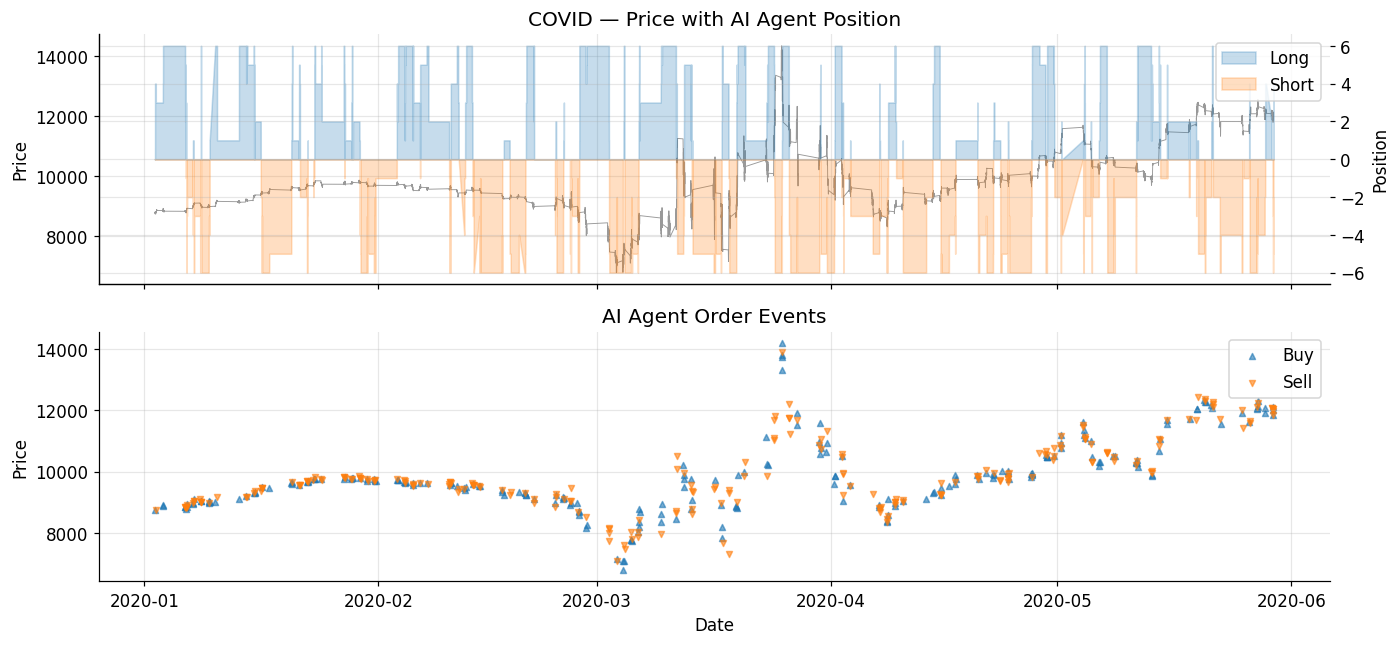

In [ ]:
# ─────────────────────────────────────────────
# SECTION 8 — AI AGENT SIGNAL INTEGRATION
# ─────────────────────────────────────────────

def load_ai_agent_signal(asset, data_dir=DATA_DIR) -> pd.DataFrame:
    meta  = ASSET_REGISTRY[asset]
    fpath = Path(data_dir) / meta['folder'] / meta['ai_agent']
    rows = []
    with open(fpath) as f:
        for line in f:
            parts = line.strip().split(',')
            if len(parts) < 5:
                continue
            try:
                dt = _excel_to_date(int(parts[0])).replace(hour=int(parts[1]), minute=int(parts[2]))
                price, position = float(parts[3]), int(parts[4])
            except (ValueError, IndexError):
                continue
            rows.append({'datetime': dt, 'ai_price': price, 'position': position})
    ai = pd.DataFrame(rows).set_index('datetime').sort_index()
    ai['order']      = ai['position'].diff().fillna(0).astype(int)
    ai['signal']     = np.sign(ai['order']).astype(int)
    ai['order_size'] = ai['order'].abs()
    return ai


def generate_signals(df, asset=ASSET, use_ai_agent=USE_AI_AGENT_SIGNAL,
                     signal_type=SIGNAL_TYPE, lookback=SIGNAL_LOOKBACK,
                     threshold=SIGNAL_THRESHOLD, tick_size=TICK_SIZE) -> pd.DataFrame:
    df = df.copy()
    if use_ai_agent:
        ai = load_ai_agent_signal(asset, DATA_DIR)
        df = df.join(ai[['position', 'order', 'signal', 'order_size']], how='left')
        for c, fill in [('signal', 0), ('order_size', 0), ('position', 0)]:
            df[c] = df[c].fillna(fill).astype(int)
    else:
        thr = threshold * tick_size
        if signal_type == 'momentum':
            # uses delta_x_intrabar (close-open) so spec delta_x stays for dir_state
            raw = df['delta_x_intrabar'].ewm(halflife=lookback, adjust=False).mean().shift(1)
        elif signal_type == 'mean_reversion':
            raw = -(df['close'] - df['close'].rolling(lookback).mean()).shift(1)
        else:
            raise ValueError(signal_type)
        df['signal']     = np.where(raw > thr, 1, np.where(raw < -thr, -1, 0)).astype(int)
        df['order_size'] = 1
        df['position']   = 0
    return df


# ── Run ──
ohlc_df = generate_signals(ohlc_df)
mode = 'AI Agent' if USE_AI_AGENT_SIGNAL else 'Synthetic Momentum'
print(f"Signal source: {mode}\nSignal distribution:")
for s, cnt in ohlc_df['signal'].value_counts().sort_index().items():
    lab = {-1: 'Sell', 0: 'Flat', 1: 'Buy'}.get(s, str(s))
    print(f"  {lab:>5} ({s:+d}): {cnt:,} ({100*cnt/len(ohlc_df):.1f}%)")

if USE_AI_AGENT_SIGNAL and ohlc_df['signal'].ne(0).any():
    nz = ohlc_df.loc[ohlc_df['signal'] != 0, 'order_size']
    print(f"\nActive signal bars: {ohlc_df['signal'].ne(0).sum():,} | "
          f"order size mean={nz.mean():.2f}, max={nz.max():.0f}")
    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    axes[0].plot(ohlc_df.index, ohlc_df['close'], color='gray', lw=0.6, alpha=0.8)
    axes[0].set(ylabel='Price', title=f'{ASSET} — Price with AI Agent Position')
    ax2 = axes[0].twinx()
    ax2.fill_between(ohlc_df.index, ohlc_df['position'].clip(lower=0), 0, alpha=0.25, color=PALETTE[0], label='Long')
    ax2.fill_between(ohlc_df.index, ohlc_df['position'].clip(upper=0), 0, alpha=0.25, color=PALETTE[1], label='Short')
    ax2.set(ylabel='Position'); ax2.legend(loc='upper right')
    buys, sells = ohlc_df[ohlc_df['signal'] == 1], ohlc_df[ohlc_df['signal'] == -1]
    axes[1].scatter(buys.index, buys['close'], marker='^', s=15, color=PALETTE[0], alpha=0.6, label='Buy')
    axes[1].scatter(sells.index, sells['close'], marker='v', s=15, color=PALETTE[1], alpha=0.6, label='Sell')
    axes[1].set(ylabel='Price', xlabel='Date', title='AI Agent Order Events'); axes[1].legend()
    plt.tight_layout(); plt.show()

---
## Section 9 — Historical Backtest

Out-of-sample only (`j ≥ test_start_idx`). For each non-Flat signal we look up the
pre-cached `ℓ*` for the current regime, place a limit at `open ± ℓ*·tick`, and
detect a fill from the same bar's OHLC. Missed limits fall back to the bar close
(`is_missed_limit=True`), so every signal results in an execution and
`improvement_ticks` can be negative. Unchanged from v1 — but now it consumes an
**uncontaminated** cache (FIX 2).

In [ ]:
# ─────────────────────────────────────────────
# SECTION 9 — HISTORICAL BACKTEST
# ─────────────────────────────────────────────

def run_backtest(df, mc_cache, test_start_idx, tick_size=TICK_SIZE) -> pd.DataFrame:
    records = []
    for j in range(test_start_idx, len(df)):
        row = df.iloc[j]
        if row['signal'] == 0:
            continue
        vs, ss, ds = int(row['vol_state']), int(row['sig_state']), int(row['dir_state'])
        if vs < 0 or ss < 0 or ds < 0:
            continue
        state, sgn = (vs, ss, ds), int(row['signal'])
        o, h, l, c = row['open'], row['high'], row['low'], row['close']
        direction = 'R_up' if sgn == -1 else 'R_dn'      # sell->R_up, buy->R_dn
        mc = mc_cache.get((state, direction))
        ell    = 0 if mc is None else mc['optimal_ell']
        is_mkt = True if mc is None else mc['is_market_order']

        if is_mkt or ell == 0:
            limit = fill = o; filled = True; missed = False; impr = 0.0; is_mkt = True
        else:
            if sgn == -1:
                limit = o + ell * tick_size; filled = h >= limit
            else:
                limit = o - ell * tick_size; filled = l <= limit
            if filled:
                fill, missed = limit, False
                impr = (fill - o) / tick_size if sgn == -1 else (o - fill) / tick_size
            else:
                fill, missed = c, True       # missed -> execute at close
                impr = (c - o) / tick_size if sgn == -1 else (o - c) / tick_size

        records.append(dict(bar_time=df.index[j], signal=sgn, vol_state=vs,
                            sig_state=ss, dir_state=ds, state=state, direction=direction,
                            open_price=o, limit_level_ticks=ell, limit_price=limit,
                            filled=filled, fill_price=fill, improvement_ticks=impr,
                            is_market_fallback=is_mkt, is_missed_limit=missed))
    return pd.DataFrame(records).set_index('bar_time') if records else pd.DataFrame()


# ── Run ──
print("Running out-of-sample backtest...")
trades_df = run_backtest(ohlc_df, mc_cache, test_start_idx)
if len(trades_df):
    n = len(trades_df); nl = (~trades_df['is_market_fallback']).sum()
    fr = trades_df.loc[~trades_df['is_market_fallback'], 'filled'].mean()
    mi = trades_df.loc[trades_df['filled'] & ~trades_df['is_market_fallback'], 'improvement_ticks'].mean()
    print(f"  Trades={n:,} | limit orders={nl:,} | market fallbacks={n-nl:,}")
    print(f"  Fill rate (limit)={fr:.2%} | mean improvement|filled={mi:.2f} ticks")
else:
    print("  No trades produced (check signal coverage / test window).")

Running out-of-sample backtest...
  Trades=179 | limit orders=179 | market fallbacks=0
  Fill rate (limit)=70.95% | mean improvement|filled=12.94 ticks


---
## Section 10 — Evaluation, Sensitivity & Results

### `[FIX 5]` — two different "net" numbers, labelled

v1's README headline defined **net vs market** as
`fill_rate × mean_improvement_filled` (the execution alpha versus a market order
at the open), but the code's *Net true improvement* averaged **all** limit trades
including the close-price fallback — a much more negative number dominated by the
directional bar return on missed fills. They are different quantities and were
conflated. v2 reports **both**, clearly named:

- **`net_vs_market`** = `fill_rate × mean_improvement_filled` — isolates execution
  quality (the headline metric).
- **`realized_avg_all`** = mean `improvement_ticks` over all limit trades incl.
  missed-fill close cost — the realized average a desk would actually book.

In [ ]:
# ─────────────────────────────────────────────
# SECTION 10a — SUMMARY METRICS   [FIX 5: report both, labelled]
# ─────────────────────────────────────────────

def compute_summary_metrics(trades, asset_label=ASSET) -> pd.Series:
    lim    = trades[~trades['is_market_fallback']]
    filled = lim[lim['filled']]
    missed = lim[lim['is_missed_limit']]
    fr  = lim['filled'].mean() if len(lim) else np.nan
    mif = filled['improvement_ticks'].mean() if len(filled) else np.nan
    return pd.Series({
        'Asset':                         asset_label,
        'Total trades':                  len(trades),
        'Limit orders placed':           len(lim),
        'Market fallbacks':              len(trades) - len(lim),
        '── Fill outcomes ──':           '',
        'Limit fill rate':               f"{fr:.2%}",
        'Missed fill rate':              f"{lim['is_missed_limit'].mean():.2%}" if len(lim) else 'N/A',
        '── Improvement vs open ──':     '',
        'Mean improvement | filled':     f"{mif:.2f} ticks",
        'Mean cost | missed fill':       f"{missed['improvement_ticks'].mean():.2f} ticks" if len(missed) else 'N/A',
        '── Headline metrics [FIX 5] ──':'',
        'net_vs_market  (alpha)':        f"{fr*mif:.2f} ticks" if len(filled) else 'N/A',
        'realized_avg_all (incl. miss)': f"{lim['improvement_ticks'].mean():.2f} ticks" if len(lim) else 'N/A',
        'Queue haircut applied':         f"{QUEUE_HAIRCUT:.0%}",
    })

if len(trades_df):
    summary = compute_summary_metrics(trades_df)
    print("=" * 52); print(f"  EXECUTION QUALITY SUMMARY — {ASSET}"); print("=" * 52)
    for k, v in summary.items():
        print(f"  {k:<34} {v}")

    print("\nPerformance by regime state (limit orders):")
    reg = (trades_df[~trades_df['is_market_fallback']]
           .groupby(['vol_state', 'sig_state'])
           .agg(n=('filled', 'count'), fill_rate=('filled', 'mean'),
                miss=('is_missed_limit', 'mean'),
                net=('improvement_ticks', 'mean')).round(3))
    print(reg.to_string())
else:
    print("No trades to summarize.")

  EXECUTION QUALITY SUMMARY — COVID
  Asset                              COVID
  Total trades                       179
  Limit orders placed                179
  Market fallbacks                   0
  ── Fill outcomes ──                
  Limit fill rate                    70.95%
  Missed fill rate                   29.05%
  ── Improvement vs open ──          
  Mean improvement | filled          12.94 ticks
  Mean cost | missed fill            -170.31 ticks
  ── Headline metrics [FIX 5] ──     
  net_vs_market  (alpha)             9.18 ticks
  realized_avg_all (incl. miss)      -40.30 ticks
  Queue haircut applied              92%

Performance by regime state (limit orders):
                       n  fill_rate   miss      net
vol_state sig_state                                
1         1          156      0.699  0.301  -34.609
          2           21      0.810  0.190  -61.810
2         2            2      0.500  0.500 -258.000


### Section 10b — ePDF visualization (Figure 2 replication)

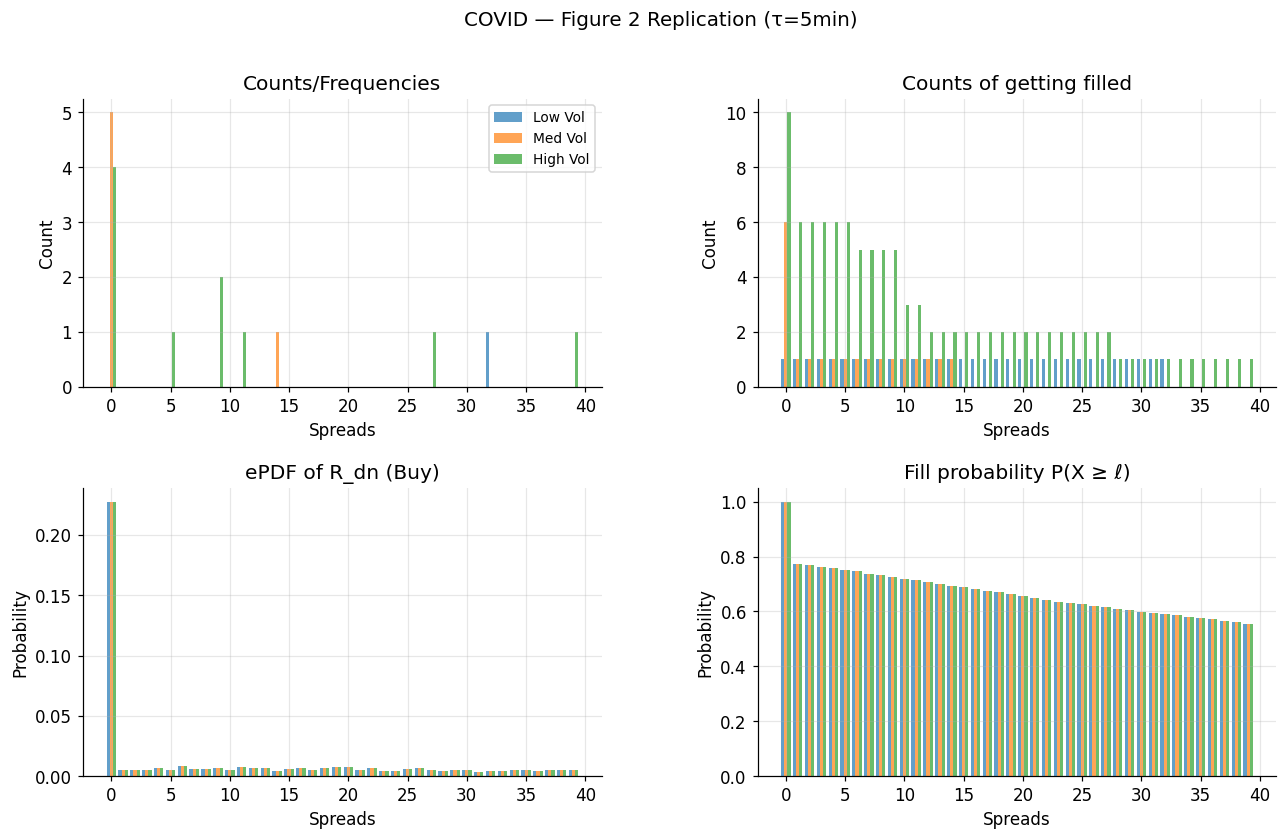

In [ ]:
# ─────────────────────────────────────────────
# SECTION 10b — ePDF VISUALIZATION (Figure 2 replication)
# ─────────────────────────────────────────────

def plot_epdf_figure2(store, states_to_show, direction='R_dn',
                      labels=None, title_prefix=''):
    labels = labels or [str(s) for s in states_to_show]
    colors = PALETTE[:len(states_to_show)]
    max_ell = min(40, max(len(store.get_pmf(s, direction)) for s in states_to_show))

    fig = plt.figure(figsize=(14, 8))
    gs = gridspec.GridSpec(2, 2, hspace=0.35, wspace=0.3)
    ax_tl, ax_bl = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
    ax_tr, ax_br = fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
    x = np.arange(max_ell); bw = 0.8 / len(states_to_show)

    for i, (st, lab, col) in enumerate(zip(states_to_show, labels, colors)):
        counts = store._counts[st][direction]
        c = np.zeros(max_ell); c[:min(len(counts), max_ell)] = counts[:max_ell]
        pmf = np.pad(store.get_pmf(st, direction)[:max_ell], (0, max(0, max_ell - len(store.get_pmf(st, direction)))))[:max_ell]
        surv = np.pad(store.get_survival(st, direction)[:max_ell], (0, max(0, max_ell - len(store.get_survival(st, direction)))))[:max_ell]
        fillc = np.array([c[e:].sum() for e in range(max_ell)])
        off = (i - len(states_to_show) / 2 + 0.5) * bw
        ax_tl.bar(x + off, c,     width=bw, color=col, alpha=0.7, label=lab)
        ax_bl.bar(x + off, pmf,   width=bw, color=col, alpha=0.7)
        ax_tr.bar(x + off, fillc, width=bw, color=col, alpha=0.7)
        ax_br.bar(x + off, surv,  width=bw, color=col, alpha=0.7)

    dl = 'R_up (Sell)' if direction == 'R_up' else 'R_dn (Buy)'
    ax_tl.set(title='Counts/Frequencies', xlabel='Spreads', ylabel='Count'); ax_tl.legend(fontsize=9)
    ax_bl.set(title=f'ePDF of {dl}', xlabel='Spreads', ylabel='Probability')
    ax_tr.set(title='Counts of getting filled', xlabel='Spreads', ylabel='Count')
    ax_br.set(title='Fill probability P(X ≥ ℓ)', xlabel='Spreads', ylabel='Probability')
    fig.suptitle(f'{title_prefix}{ASSET} — Figure 2 Replication (τ={TAU}min)', fontsize=13)
    plt.show()

plot_epdf_figure2(epdf_store, [(1, 0, 1), (1, 1, 1), (1, 2, 1)], direction='R_dn',
                  labels=['Low Vol', 'Med Vol', 'High Vol'])

### Section 10c — Calibration & cumulative improvement (gross vs net)

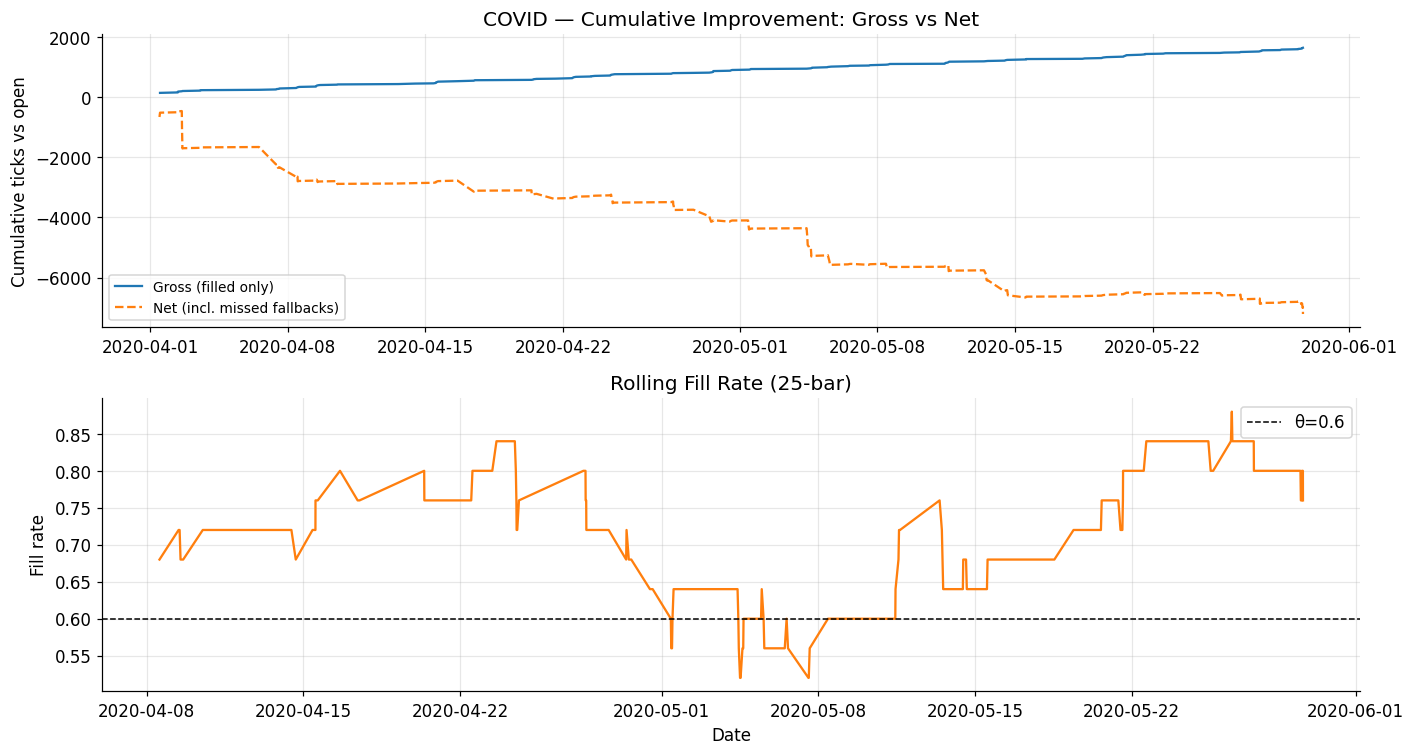

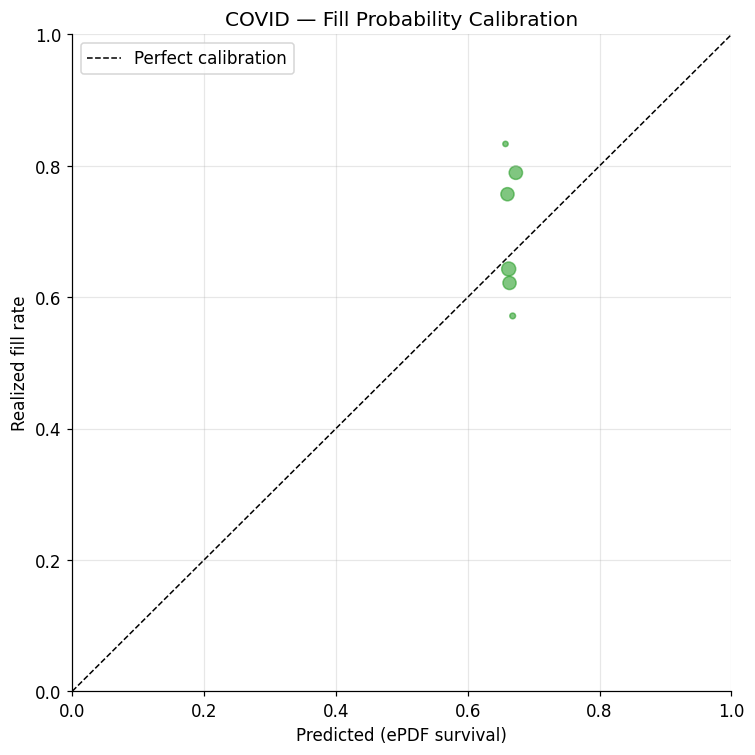

In [ ]:
# ─────────────────────────────────────────────
# SECTION 10c — CALIBRATION & TIME-SERIES
# ─────────────────────────────────────────────
if len(trades_df):
    all_lim = trades_df[~trades_df['is_market_fallback']].copy()
    filled  = all_lim[all_lim['filled']]

    fig, axes = plt.subplots(2, 1, figsize=(13, 7))
    axes[0].plot(filled.index, filled['improvement_ticks'].cumsum(),
                 color=PALETTE[0], label='Gross (filled only)')
    axes[0].plot(all_lim.index, all_lim['improvement_ticks'].cumsum(),
                 color=PALETTE[1], ls='--', label='Net (incl. missed fallbacks)')
    axes[0].legend(fontsize=9)
    axes[0].set(title=f'{ASSET} — Cumulative Improvement: Gross vs Net',
                ylabel='Cumulative ticks vs open')
    axes[1].plot(all_lim.index, all_lim['filled'].rolling(25).mean(), color=PALETTE[1])
    axes[1].axhline(FILL_PROB_THRESHOLD, color='k', ls='--', lw=1, label=f'θ={FILL_PROB_THRESHOLD}')
    axes[1].set(title='Rolling Fill Rate (25-bar)', ylabel='Fill rate', xlabel='Date'); axes[1].legend()
    plt.tight_layout(); plt.show()

    # Calibration: predicted survival vs realized fill, by (state, ell)
    rec = []
    for (st, d), g in all_lim.groupby(['state', 'direction']):
        for ell, sub in g.groupby('limit_level_ticks'):
            if len(sub) < 5: continue
            rec.append({'predicted': epdf_store.fill_prob(st, d, int(ell)),
                        'realized': sub['filled'].mean(), 'n': len(sub)})
    calib = pd.DataFrame(rec)
    if not calib.empty:
        fig, ax = plt.subplots(figsize=(7, 7))
        ax.scatter(calib['predicted'], calib['realized'], s=calib['n']*2, alpha=0.6, color=PALETTE[2])
        ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect calibration')
        ax.set(title=f'{ASSET} — Fill Probability Calibration',
               xlabel='Predicted (ePDF survival)', ylabel='Realized fill rate',
               xlim=(0, 1), ylim=(0, 1)); ax.legend(); plt.tight_layout(); plt.show()
    else:
        print("Not enough (state, ell) groups for a calibration plot.")

### Section 10d — Sensitivity analysis

A τ × threshold sweep, holding everything else at the Section-0 defaults (so the
signal source and `VOL_PROXY` are the configured ones). For the synthetic test
assets this runs in seconds; for real NQ/GC it is the slowest cell — see
`TESTING.md` for guidance on trimming the grid while iterating.

Sensitivity — COVID: fill rate by (τ, threshold)
threshold    0.5    0.6    0.7
tau                           
5          0.665  0.709  0.720
10         0.693  0.705  0.773
15         0.734  0.828  0.844

Sensitivity — COVID: net_vs_market (ticks) by (τ, threshold)
threshold     0.5     0.6     0.7
tau                              
5          15.832   9.179   3.497
10         47.705  32.375  19.864
15         71.094  69.297  43.031


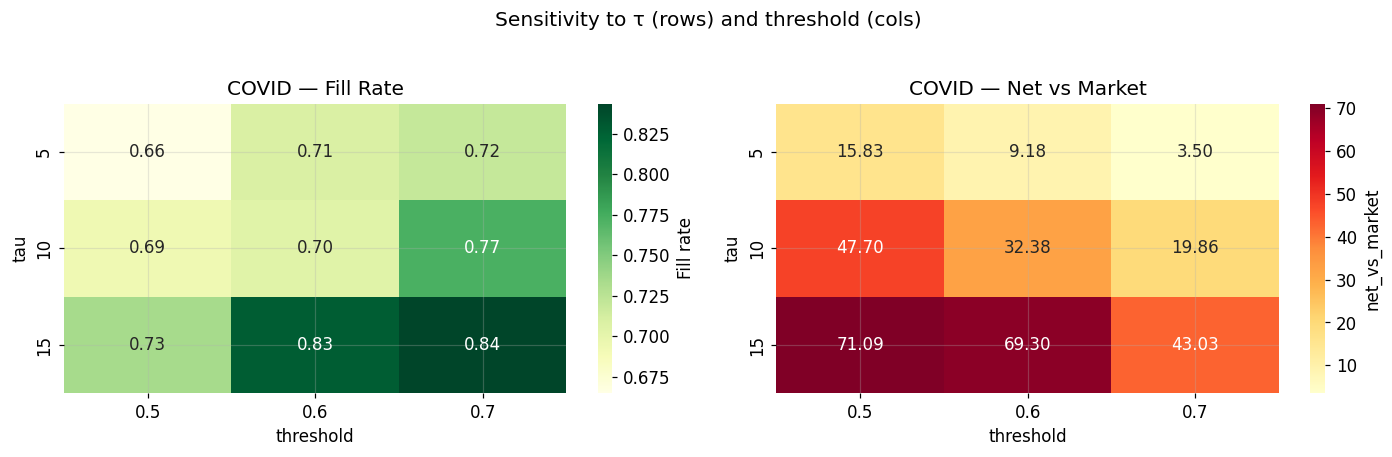

In [ ]:
# ─────────────────────────────────────────────
# SECTION 10d — SENSITIVITY ANALYSIS
# ─────────────────────────────────────────────
import io, sys

def run_pipeline(asset, tau, half_life, n_states, fill_threshold,
                 smoothing=SMOOTHING_ALPHA, vol_proxy=VOL_PROXY, objective=MC_OBJECTIVE):
    tick = ASSET_REGISTRY[asset]['tick_size']
    _raw  = load_data(asset, DATA_DIR, MIN_BARS_PER_DAY)
    _ohlc = compute_ranges(build_ohlc(_raw, tau), tick)
    _ohlc = compute_ewma_states(_ohlc, tick_size=tick, half_life=half_life,
                                m_states=n_states, n_states=n_states, k_states=n_states,
                                vol_proxy=vol_proxy)
    _ohlc = generate_signals(_ohlc, asset=asset, tick_size=tick)
    _store, _tsi = build_epdf(_ohlc, smoothing_alpha=smoothing, min_samples=MIN_EPDF_SAMPLES)
    _cache = build_mc_frontier_cache(_store, n_states, n_states, n_states,
                                     fill_prob_threshold=fill_threshold, objective=objective,
                                     bootstrap_reps=0)   # CI not needed in sweeps -> fast
    _tr = run_backtest(_ohlc, _cache, _tsi, tick_size=tick)
    if _tr.empty:
        return dict(fill_rate=np.nan, mean_improvement=np.nan, net_vs_market=np.nan, n_trades=0)
    lim = _tr[~_tr['is_market_fallback']]; fl = lim[lim['filled']]
    fr  = lim['filled'].mean() if len(lim) else np.nan
    mif = fl['improvement_ticks'].mean() if len(fl) else np.nan
    return dict(fill_rate=fr, mean_improvement=mif,
                net_vs_market=fr*mif if len(fl) else np.nan, n_trades=len(lim))

TAU_GRID    = [5, 10, 15]      # expand to [5,10,15,30] for the report
THRESH_GRID = [0.50, 0.60, 0.70]  # expand to add 0.80 for the report
rows = []
for tv in TAU_GRID:
    for th in THRESH_GRID:
        old = sys.stdout; sys.stdout = io.StringIO()
        try:    res = run_pipeline(ASSET, tv, HALF_LIFE, M_STATES, th)
        finally: sys.stdout = old
        rows.append({'tau': tv, 'threshold': th, **res})
sens = pd.DataFrame(rows)

print(f"Sensitivity — {ASSET}: fill rate by (τ, threshold)")
print(sens.pivot(index='tau', columns='threshold', values='fill_rate').round(3).to_string())
print(f"\nSensitivity — {ASSET}: net_vs_market (ticks) by (τ, threshold)")
print(sens.pivot(index='tau', columns='threshold', values='net_vs_market').round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(sens.pivot(index='tau', columns='threshold', values='fill_rate'),
            annot=True, fmt='.2f', cmap='YlGn', ax=axes[0], cbar_kws={'label': 'Fill rate'})
sns.heatmap(sens.pivot(index='tau', columns='threshold', values='net_vs_market'),
            annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'net_vs_market'})
axes[0].set(title=f'{ASSET} — Fill Rate'); axes[1].set(title=f'{ASSET} — Net vs Market')
plt.suptitle('Sensitivity to τ (rows) and threshold (cols)', y=1.03)
plt.tight_layout(); plt.show()

### Section 10e — Cross-asset comparison

Runs the identical pipeline on two assets and tabulates execution quality. By
default it compares the two synthetic assets so it runs anywhere; switch the list
to `['NQ', 'GC']` once the real data is in place.

In [ ]:
# ─────────────────────────────────────────────
# SECTION 10e — CROSS-ASSET COMPARISON
# ─────────────────────────────────────────────
COMPARE = ['TINY', 'COVID'] if ASSET in ('TINY', 'SMALL', 'COVID') else ['NQ', 'GC']
print(f"Cross-asset comparison: {COMPARE}")
rows = []
for a in COMPARE:
    old = sys.stdout; sys.stdout = io.StringIO()
    try:    res = run_pipeline(a, TAU, HALF_LIFE, M_STATES, FILL_PROB_THRESHOLD)
    finally: sys.stdout = old
    rows.append({'Asset': a, 'Tick': ASSET_REGISTRY[a]['tick_size'],
                 'Limit trades': res['n_trades'],
                 'Fill rate': f"{res['fill_rate']:.2%}" if not np.isnan(res['fill_rate']) else 'N/A',
                 'Impr|filled': f"{res['mean_improvement']:.2f}" if not np.isnan(res['mean_improvement']) else 'N/A',
                 'net_vs_market': f"{res['net_vs_market']:.2f}" if not np.isnan(res['net_vs_market']) else 'N/A'})
print(pd.DataFrame(rows).set_index('Asset').to_string())

Cross-asset comparison: ['TINY', 'COVID']


       Tick  Limit trades Fill rate Impr|filled net_vs_market
Asset                                                        
TINY   0.25            20    65.00%       10.15          6.60
COVID  0.25           179    70.95%       12.94          9.18


---
## Model Limitations (carried over, with v2 notes)

| Limitation | Status in v2 |
|---|---|
| Queue position | Still approximated by `QUEUE_HAIRCUT`. Bootstrap CI is pre-haircut (documented in §7). |
| OHLC-only intra-bar path | Unchanged; fills detected from bar OHLC. |
| Single-period execution | Missed limits → close fallback; tracked via `is_missed_limit`. |
| Close-fallback bias | Now explicitly separated from execution alpha via `net_vs_market` vs `realized_avg_all` (FIX 5). |
| Static ePDF | Still fit once on the in-sample window — but now *only* in-sample (FIX 2). A rolling update remains future work. |
| i.i.d. bar assumption | Time-based non-overlapping windows (FIX 4) preserve the independence argument. |

**Direction state caveat (open item).** With `DIR_THRESHOLD=1` tick, calm regimes
push most bars into "flat," so the direction dimension can be weakly informative
on quiet assets. A τ-adaptive threshold is a reasonable extension if you find the
`dir` dimension is not separating the ePDFs.